In [1]:
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import numpy as np
import xarray as xr
from matplotlib import pyplot as plt
from matplotlib import rcParams, colors
from matplotlib import ticker as mticker
import geopandas as gpd
rcParams.update({'figure.autolayout': False})
import os
import wrf
import cmcrameri as cm
#import pymannkendall as mk
from cartopy import crs as ccrs
from cartopy.feature import ShapelyFeature
import cartopy.feature as cfeature
from cartopy.io.shapereader import Reader
from cartopy.mpl.gridliner import LATITUDE_FORMATTER, LONGITUDE_FORMATTER
from shapely.geometry import mapping
import glob
import pandas as pd
import pickle
import dask
import rioxarray
import xesmf as xe
import dask
from dask.distributed import Client, LocalCluster
from dask import delayed
import dask.array as da
from dask_jobqueue import PBSCluster
import xarray as xr
from concurrent.futures import ProcessPoolExecutor
import calendar
import zarr
import h5netcdf

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [2]:
cluster = PBSCluster(
    cores=1, 
    memory='300GB',  
    processes=6,  
    queue='casper',  
    local_directory='/glade/derecho/scratch/adixit/tmp/',  
    resource_spec='select=1:ncpus=6:mem=300GB', 
    account='UCOR0105', 
    walltime='1:00:00', 

)

cluster.scale(jobs=1)  
client = Client(cluster)

In [4]:
client

<Client: 'tcp://128.117.208.191:46057' processes=6 threads=6, memory=279.42 GiB>

In [5]:
ds_t2 = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/AMJJAS_anom/VAR_2T_ERA5_India_AMJJAS_anom.nc')
ds_da = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/L1/dyn_adj/MSL_1950/dyn_adj_ERA5_India_50_34_20_74.nc', chunks='auto')

ds_msl = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/AMJJAS_anom/MSL_ERA5_India_AMJJAS_anom.nc')
ds_t2_masked = ds_t2.sel(time=ds_da.time, lat=ds_da.lat, lon=ds_da.lon)
ds_diff = dask.delayed(ds_t2_masked['anom'] - ds_da['dynamic'])
ds_diff = ds_diff.compute()

/glade/work/adixit/conda-envs/dask/lib/python3.10/site-packages/xarray/core/indexing.py:1625: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array[indexer]
  value = value[(slice(None),) * axis + (subkey,)]


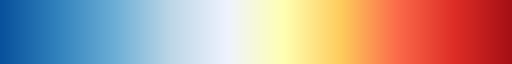

In [6]:
from matplotlib.colors import LinearSegmentedColormap
combined_colors = ['#08519c', '#3182bd', '#6baed6', '#bdd7e7', '#eff3ff','#ffffb2','#fecc5c','#fb6a4a','#de2d26','#a50f15']
def create_gradient_colormap(n_colors, color_list=combined_colors):
    return LinearSegmentedColormap.from_list("custom_gradient", color_list, N=n_colors)
cmap1 = create_gradient_colormap(256,combined_colors)
cmap1

In [7]:
def plot_simulated(llon,llat,prec,row,col,levs,cmap1,shape_feature,ax1):
    #plt.style.use('classic')
    #plt.title(title)
    #ax1.("Y - axis")
    s=ax1.axes
    g=s.gridlines()
    g.bottom_labels=False
    g.left_labels=True

    if row == 0:
        g.bottom_labels=True
    if col>0:
        g.left_labels=False
    g.ylines=False
    g.xlines=False
    #g.xlocator = mticker.FixedLocator(np.arange(-115,-99,7))
    #g.ylocator = mticker.FixedLocator(np.arange(30,50,5))
    g.xformatter = LONGITUDE_FORMATTER
    g.yformatter = LATITUDE_FORMATTER
    g.xlabel_style = {'size':7.5, 'color': 'k'}
    g.ylabel_style = {'size': 7.5, 'color': 'k'}  
    pc1 = plt.contourf(llon,llat,prec,cmap=cmap1,transform=ccrs.PlateCarree(), levels=levs, extend='both')   
    #pc1 = plt.contourf(llon,llat,prec,colors=cmap1,transform=ccrs.PlateCarree(), levels=levs)   
    #fname = '/media/ankur/f764cec3-536e-4e1d-b58c-9442c881e0a0/ankur/VIC_DATA/BasinBoundary/Beas.shp'
    
    ax1.add_feature(shape_feature, edgecolor='k', lw=0.75)
    return pc1


In [8]:
times = slice('2024-05-25','2024-06-01')

In [9]:
import matplotlib.patches as patches

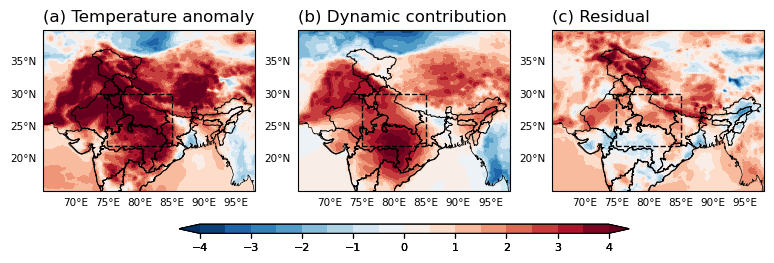

In [10]:
f = plt.figure(figsize=(9, 3))
gs1 = gridspec.GridSpec(1, 3)
gs1.update(left=0.099,  bottom=0.14, wspace=0.2 ,hspace=0.16)

levs = np.arange(-4,4.1,0.5)
levdiff = np.arange(-4,4.1,0.2)
c1diff =  cmap1
c1 = 'RdBu_r'#cmap
months=[5,6]

shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
shape_feature = ShapelyFeature(Reader(shp_file).geometries(), ccrs.PlateCarree(),edgecolor='black', facecolor='none',lw=0.5)

datalist = [ds_t2['anom'],ds_da['dynamic'],ds_diff]
panel_title = ['(a) Temperature anomaly', '(b) Dynamic contribution', '(c) Residual']

for i in range(3):
    
    ax1 = f.add_subplot(gs1[0,i],projection=ccrs.PlateCarree())
    ax1.coastlines(resolution='50m', linewidth=0.5, color='black')
    #ax1.add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='gray')
    data = datalist[i]
    data = data.sel(time=times).mean(dim='time')
    pc = plot_simulated(data.lon,data.lat,data,0,0,levs,c1,shape_feature,ax1)
    #plt.title("Maximum Heatwave Duration: 2024 : "+''.join(map(str, months)))
    ax1.set_xlim([65,98])
    ax1.set_ylim([15,40])
    ax1.set_title(panel_title[i],loc='left')
    cbar_ax = f.add_axes([0.25, 0.1,0.5, 0.03])
    cb = plt.colorbar(pc, cax=cbar_ax,orientation="horizontal")
    cb.ax.tick_params(labelsize=8)

    msl_data = ds_msl['anom'].sel(time=times).std(dim='time')
    
    box_lon = slice(75, 85)
    box_lat = slice(30, 22)
    rectangle2 = patches.Rectangle((75, 22), 10, 8, edgecolor='k', facecolor='None', linewidth=1, linestyle='--')
    
    ax1.add_patch(rectangle2)
#plt.savefig("Fig1-event1.pdf",dpi=300,format='pdf',transparent=True)

In [12]:
times = slice('2024-06-10','2024-06-20')

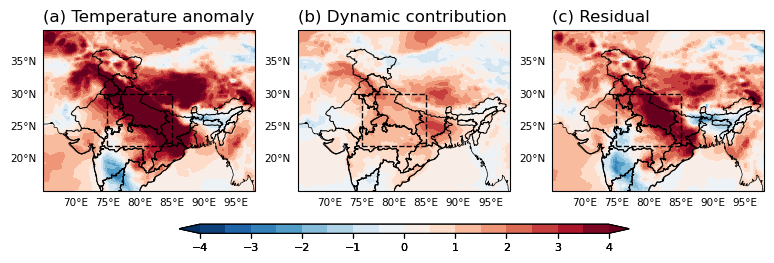

In [13]:
f = plt.figure(figsize=(9, 3))
gs1 = gridspec.GridSpec(1, 3)
gs1.update(left=0.099,  bottom=0.14, wspace=0.2 ,hspace=0.16)

levs = np.arange(-4,4.1,0.5)
levdiff = np.arange(-4,4.1,0.2)
c1diff =  cmap1
c1 = 'RdBu_r'#cmap
months=[5,6]

shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
shape_feature = ShapelyFeature(Reader(shp_file).geometries(), ccrs.PlateCarree(),edgecolor='black', facecolor='none',lw=0.5)

datalist = [ds_t2['anom'],ds_da['dynamic'],ds_diff]
panel_title = ['(a) Temperature anomaly', '(b) Dynamic contribution', '(c) Residual']

for i in range(3):
    
    ax1 = f.add_subplot(gs1[0,i],projection=ccrs.PlateCarree())
    ax1.coastlines(resolution='50m', linewidth=0.5, color='black')
    data = datalist[i]
    data = data.sel(time=times).mean(dim='time')
    pc = plot_simulated(data.lon,data.lat,data,0,0,levs,c1,shape_feature,ax1)
    ax1.set_title(panel_title[i],loc='left')
    #plt.title("Maximum Heatwave Duration: 2024 : "+''.join(map(str, months)))
    ax1.set_xlim([65,98])
    ax1.set_ylim([15,40])
    cbar_ax = f.add_axes([0.25, 0.1,0.5, 0.03])
    cb = plt.colorbar(pc, cax=cbar_ax,orientation="horizontal")
    cb.ax.tick_params(labelsize=8)
    box_lon = slice(75, 85)
    box_lat = slice(30, 22)
    rectangle2 = patches.Rectangle((75, 22), 10, 8, edgecolor='k', facecolor='None', linewidth=1, linestyle='--')

    ax1.add_patch(rectangle2)
#plt.savefig("Fig1-event2.pdf",dpi=300,format='pdf',transparent=True)